# Kerala University Affiliated Colleges — Web Scraping Project

## 1. Introduction

### Project Overview
This project aims to collect information about colleges affiliated with the University of Kerala using web scraping techniques in Python. The collected information will be organized into a structured dataset for data cleaning and analysis.

### Objectives
- Understand the structure of the university's affiliated colleges website.
- Extract college information using Python web scraping techniques.
- Handle missing values, inconsistent formats, and duplicate records.
- Store the collected data in CSV or Excel format.
- Generate summary statistics and visualizations.
- Identify insights from the collected data.

### Target Website
**Source:** University of Kerala — Affiliated Colleges Portal

**URL:** https://www.keralauniversity.ac.in/affiliated-colleges

### Data to Be Collected
1. College Name
2. Address
3. Contact Number
4. Email Address
5. Website URL

Optional fields, if available:
- District
- College Type
- Principal Name

In [2]:
import requests
from bs4 import BeautifulSoup

import pandas as pd
import matplotlib.pyplot as plt

In [3]:
url = "https://www.keralauniversity.ac.in/affiliated-colleges"
response = requests.get(url)
print(response.status_code)

200


In [4]:
soup = BeautifulSoup(response.text, "html.parser")
print(soup.title.get_text(strip=True))

University of Kerala


In [5]:
headings = soup.find_all("h4")

for heading in headings:
    print(heading.get_text(" ", strip=True))

University of Kerala
Affiliated Colleges
A. J. College of Science and Technology, Thonnakkal
All Saints' College, Thiruvananthapuram
Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram
Ayyankali Memorial Arts and Science College, Kuryottumala, Vettithitta P. O., Pathanapuram
B.N.V. College of Teacher Education, Thiruvallam, Thiruvananthapuram
Baby John Memorial Govt. College, Chavara
Badhiriya B.Ed. Training College, Velichikkala, Kollam
Baselios Marthoma Mathews II Training College, Kottarakara
Bishop Jerome School of Architecture, Fathima College Road, Kollam
Bishop Jesudasan CSI Arts & Science College, Mulayara, Thiruvananthapuram
Bishop Moore College for the Hearing Impaired, Manakala, Adoor
Bishop Moore College, Mavelikkara, Alappuzha
Buddha College of Teacher Education, Cheppad, Muthukulam North, Alappuzha
C. H. M. M. College for Advanced Studies, Chavarcode, Varkala
Carmel College, Muhamma, Alappuzha
Christ College, Vizhinjam, Thiruvananthapuram
Christ Nagar Ch

In [6]:
for heading in soup.find_all("h4"):
    link = heading.find("a")

    if link:
        print("College:", link.get_text(" ", strip=True))
        print("Website URL:", link.get("href"))
        print("-" * 50)

College: A. J. College of Science and Technology, Thonnakkal
Website URL: http://www.ajcollege.in
--------------------------------------------------
College: All Saints' College, Thiruvananthapuram
Website URL: http://www.allsaintscollege.ac.in
--------------------------------------------------
College: Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram
Website URL: http://www.aimmba.com
--------------------------------------------------
College: Ayyankali Memorial Arts and Science College, Kuryottumala, Vettithitta P. O., Pathanapuram
Website URL: http://www.akmascollege.com
--------------------------------------------------
College: B.N.V. College of Teacher Education, Thiruvallam, Thiruvananthapuram
Website URL: http://www.bnvtrust.org
--------------------------------------------------
College: Baby John Memorial Govt. College, Chavara
Website URL: http://www.bjmgovtcollege.ac.in
--------------------------------------------------
College: Badhiriya B.Ed. Training 

In [9]:
college = soup.find(
    "h4",
    string=lambda text: text and "A. J. College of Science" in text
)

if college:
    print(college.parent.parent.prettify()[:5000])

<div class="col-sm-12 col-md-12 col-lg-12" style="border-bottom:1px solid #999; padding-bottom:15px; padding-top:15px;">
 <div class="school-list-item">
  <h4 style="text-align:left">
   <a href="http://www.ajcollege.in" style="color:#FFF; text-decoration:none" target="_blank">
    A. J. College of Science and Technology, Thonnakkal
   </a>
  </h4>
  <p style="font-weight:bold;">
   Thiruvananthapuram
   <font color="orange">
    |
   </font>
   Estd. 
            	    							1995
   <font color="orange">
    |
   </font>
   Self Financing
  </p>
  <p style="font-size:85%; padding-right:19px;">
   A. J. College of Science and Technology was established in 1995 on the side of national high way near Kumaran Asan Memorial. It was the fulfillment of a long cherished desire of the management to start an institution of higher education offering degree and post graduate cour...
  </p>
  <div class="col-sm-12 col-md-12 col-lg-12" style="padding-left:0px; margin-top:10px;">
   <div class="col-m

### HTML Inspection Findings

The college directory displays each college inside a `div` with the class `school-list-item`.

- **College Name:** Available as text inside an `<a>` element nested within an `<h4>` element.
- **Website URL:** Available in the `href` attribute of the college's website link.
- **Address:** A location or district is displayed in a `<p>` element, but a complete address has not yet been identified.
- **Contact Number:** Not found in the inspected directory HTML.
- **Email Address:** Not found in the inspected directory HTML.

In [7]:
for link in soup.find_all("a", href=True):
    text = link.get_text(" ", strip=True).lower()

    if any(word in text for word in ["next", "previous"]):
        print("Link text:", link.get_text(" ", strip=True))
        print("URL:", link["href"])

Link text: Previous Question Papers
URL: previous-qp


In [8]:
print("HTML length:", len(response.text))

print("\nPage title:")
print(soup.title.get_text(strip=True))

print("\nCollege headings found:", len(soup.find_all("h4")))

HTML length: 601488

Page title:
University of Kerala

College headings found: 206


### Static or Dynamic Content

The HTML downloaded using Python Requests contains college headings that can be identified using BeautifulSoup. This indicates that at least some college information is available in the initial HTML response. Further inspection is required to determine whether any additional content is loaded dynamically using JavaScript.

In [10]:
details_form = college.find_parent(
    "div", class_="school-list-item"
).find("form")

print("Form action:", details_form.get("action"))
print("Form method:", details_form.get("method"))

for field in details_form.find_all("input"):
    print(
        "Input name:", field.get("name"),
        "| Value:", field.get("value"),
        "| Type:", field.get("type")
    )

Form action: affiliated-college-details
Form method: post
Input name: collegeCol | Value: 5 | Type: hidden
Input name: None | Value:   Read More ➧ | Type: submit


In [11]:
print(
    college.find_parent("div", class_="school-list-item")
    .prettify()[-2000:]
)

<div class="school-list-item">
 <h4 style="text-align:left">
  <a href="http://www.ajcollege.in" style="color:#FFF; text-decoration:none" target="_blank">
   A. J. College of Science and Technology, Thonnakkal
  </a>
 </h4>
 <p style="font-weight:bold;">
  Thiruvananthapuram
  <font color="orange">
   |
  </font>
  Estd. 
            	    							1995
  <font color="orange">
   |
  </font>
  Self Financing
 </p>
 <p style="font-size:85%; padding-right:19px;">
  A. J. College of Science and Technology was established in 1995 on the side of national high way near Kumaran Asan Memorial. It was the fulfillment of a long cherished desire of the management to start an institution of higher education offering degree and post graduate cour...
 </p>
 <div class="col-sm-12 col-md-12 col-lg-12" style="padding-left:0px; margin-top:10px;">
  <div class="col-md-4" style="float:left; padding-left:0px; max-width:50%">
   <a href="http://www.ajcollege.in" style="color:#FFF;" target="_blank">
    www.ajc

## 2. Website Analysis

### Website Structure
The University of Kerala affiliated colleges portal displays college records in alphabetical order. Each college listing is contained in a `div` with the class `school-list-item`.

### HTML Inspection Findings
- **College Name:** Text inside an `<a>` element nested within an `<h4>` element.
- **Website URL:** Available in the `href` attribute of the college website link.
- **Location:** Displayed in a `<p>` element alongside the establishment year and college type.
- **Address, Contact Number and Email Address:** Not identified in the inspected directory HTML. These fields require further investigation.

### Accessing Individual College Details
Each listing contains a form with the action `affiliated-college-details` and method `post`. The form includes a hidden input named `collegeCol`, which appears to identify the selected college. The form response must be inspected to determine how additional details can be extracted.

### Pagination and Content Loading
The directory's pagination and content-loading behavior must be confirmed through inspection of the page and its links. The presence of college information in the downloaded HTML indicates that at least some records are available in the initial response.


In [12]:
from urllib.parse import urljoin

# Select the first college listing
item = soup.select_one("div.school-list-item")

# Find its Read More form
form = item.find("form", action="affiliated-college-details")

# Get the details page URL
details_url = urljoin(url, form.get("action"))

# Collect the hidden form data
payload = {
    field.get("name"): field.get("value")
    for field in form.find_all("input", type="hidden")
    if field.get("name")
}

print("Details URL:", details_url)
print("Form data:", payload)

Details URL: https://www.keralauniversity.ac.in/affiliated-college-details
Form data: {'collegeCol': '5'}


In [13]:
# Submit the Read More form
details_response = requests.post(
    details_url,
    data=payload,
    headers={"Referer": url}
)

print("Status code:", details_response.status_code)
print("Response length:", len(details_response.text))

# Parse the response
details_soup = BeautifulSoup(details_response.text, "html.parser")

# Display the page title
print("Page title:", details_soup.title.get_text(strip=True)
      if details_soup.title else "No title found")

# Preview the page text
print(details_soup.get_text(" ", strip=True)[:1500])

Status code: 200
Response length: 97149
Page title: University of Kerala
University of Kerala University of Kerala Home About ▾ ▾ General ▾ ▾ Grievance Redressal A-Z index Instrumentation Facility (CLIF) Site map Overview University Act and Statutes Institutional Development Plan Recognition / Approval Annual Reports NAAC Institutional Data (NIRF) QS Rankings ARIIA Report Annual Accounts Budget Estimate Vision & Mission Founder Why KU? Facts and Figures Administration ▾ ▾ Organogram Chart Chancellor Pro-Chancellor Vice Chancellor Registrar Finance Officer Controller of Examinations Ombudsperson Succession List ▾ ▾ Chancellors Pro-Chancellors Vice Chancellors Pro-Vice Chancellors Executive Bodies ▾ ▾ Senate Syndicate Statutory Officers Academic Council Boards of Studies Finance Committee Administrative Staff ▾ ▾ Directors Other Officers Personal Staff Joint Registrars Deputy Registrars Assistant Registrars Librarians Academic Leadership ▾ ▾ Deans of Faculties Faculties School Directors 

In [14]:
# Check whether the response contains college details
print("College name found:", "A. J. College of Science and Technology" in details_response.text)

# Search for the college ID in the response
print("College ID found:", "collegeCol" in details_response.text)

# Display text containing college-related keywords
page_text = details_soup.get_text(" ", strip=True)

for word in ["Address", "Email", "Phone", "Contact", "Principal"]:
    print(word, ":", word.lower() in page_text.lower())

College name found: True
College ID found: False
Address : True
Email : True
Phone : False
Contact : True
Principal : True


In [15]:
# Find the college name in the returned page
college_heading = details_soup.find(
    string=lambda text: text and
    "A. J. College of Science and Technology" in text
)

if college_heading:
    print("College heading found:")
    print(college_heading.parent)
else:
    print("College heading not found in the parsed page.")

College heading found:
<h6 class="route-link active ml-2">A. J. College of Science and Technology, Thonnakkal</h6>


In [16]:
# Display the HTML surrounding the college heading
print(college_heading.parent.parent.parent.prettify()[:5000])

<div class="uni-feed">
 <div class="d-flex mb-5 route" style="margin-bottom: 1rem !important; margin-top:2rem !important;">
  <h6 class="route-link">
   Home
   <i class="fa fa-chevron-right ml-2">
   </i>
  </h6>
  <h6 class="route-link ml-2">
   Academics
   <i class="fa fa-chevron-right ml-2">
   </i>
  </h6>
  <h6 class="route-link ml-2">
   <a href="affiliated-colleges">
    Affiliated Colleges
   </a>
   <i class="fa fa-chevron-right ml-2">
   </i>
  </h6>
  <h6 class="route-link active ml-2">
   A. J. College of Science and Technology, Thonnakkal
  </h6>
 </div>
</div>



In [17]:
# Find the main content area of the page
print(details_soup.get_text(" ", strip=True)[2000:5000])

 Library Hostels Observatory Cafeteria University Level Ethics Committee ▾ ▾ University Level Ethics Committee Checklist for Submission of Research Protocols MoU Shodhganga Shodhgangotri List of Awardees ▾ ▾ DSc. DLitt. LLD Post Doctorate Doctorate Other Awards Others ▾ ▾ IPR Technology Transfer Consultancy Projects Funding Agencies Student Life ▾ ▾ Sports Services ▾ ▾ NSS NCC Dept. of Student Services Placement Cell Finishing School Startups Centre Career Guidance University Union Continuing Education Paliative Care Unit Youth Festival Facilities for differently-abled Hostel Fellowship / Scholarship Students Grievance Redressal Committee (SGRC) Health Centre Internal Complaints Committee Anti-Ragging Cell with Helpline Number Equal Opportunity Cell Socio-Economically Disadvantaged Group Cell (SEDG) Academic Bank of Credits Examinations Campus Harmony ▾ ▾ e-Samadhaan Internal Quality Assurance Cell DigiLocker NAD Portal National Scholarship Portal Campus Life ▾ ▾ Transport IT Facilitie

In [18]:
# Find the main college information section
college_section = details_soup.find(
    string=lambda text: text and
    "A. J. College of Science and Technology" in text
)

# Display the parent elements to inspect the HTML structure
if college_section:
    print(college_section.find_parent().parent.parent.parent.prettify()[:8000])

<div class="university-container">
 <style>
  .university-container .university-custom-home nav {
    line-height: 2.5;
}
 </style>
 <div class="university-custom-home">
  <nav class="navbar-dark" id="menu">
   <!-- <div class="container"> -->
   <div class="actions">
    <div class="action-items">
     <button aria-controls="navbarSupportedContent" aria-expanded="false" aria-label="Toggle navigation" class="drop-icon navbar-toggler" data-target="#navbarSupportedContent" data-toggle="collapse" type="button">
      <label for="tm" id="toggle-menu">
       <span class="drop-icon">
       </span>
       <span class="navbar-toggler-icon">
       </span>
      </label>
     </button>
     <svg height="30pt" viewbox="0 0 50.436 53.87" width="30pt" xmlns="http://www.w3.org/2000/svg">
      <path d="M5252.01,6827.287l.336-.6,1.561.932a3.221,3.221,0,0,0,.493.264.512.512,0,0,0,.388-.013.746.746,0,0,0,.33-.334.714.714,0,0,0,.112-.446.479.479,0,0,0-.161-.306,3.567,3.567,0,0,0-.475-.318l-1.593-.953

In [19]:
# Find the college description
description = details_soup.find(
    string=lambda text: text and
    "The college aims" in text
)

if description:
    print(description.parent.parent.prettify()[:4000])
else:
    print("College description not found.")

<div class="category-list">
 <h2 style="margin-bottom:18px;">
  A. J. College of Science and Technology, Thonnakkal
 </h2>
 <div class="col-sm-12 col-md-12 col-lg-12" style=" float:left; margin-right:20px; padding-left:0px; margin-bottom:20px;	">
  <img alt="Photo of A. J. College of Science and Technology, Thonnakkal" class="img-responsive" height="325" src="images/colleges/ajcollege.jpg" width="444"/>
 </div>
 <p style="font-weight:bold; margin-bottom:20px !important;">
  Thiruvananthapuram
  <font color="orange">
   |
  </font>
  Estd.
								                        1995
  <font color="orange">
   |
  </font>
  Self Financing
 </p>
 <p style="text-align:justify; padding-right:19px;">
  A. J. College of Science and Technology was established in 1995 on the side of national high way near Kumaran Asan Memorial. It was the fulfillment of a long cherished desire of the management to start an institution of higher education offering degree and post graduate courses in professional area. 

In [20]:
# Find the main college information section
college_info = details_soup.find("div", class_="category-list")

# Extract college name
college_name = college_info.find("h2").get_text(strip=True)

# Extract all text from the contact information section
contact_section = college_info.find("span")
contact_text = contact_section.get_text(" ", strip=True)

# Extract website URL
website_link = contact_section.find("a", href=True)
website_url = website_link["href"] if website_link else None

print("College Name:", college_name)
print("Contact Information:", contact_text)
print("Website URL:", website_url)

College Name: A. J. College of Science and Technology, Thonnakkal
Contact Information: Contact Address : The Principal, A.J. college of Science and Technology, Thonnakkal, Thiruvananthapuram, Kerala - 695 317 Contact No : 0471 2618644 | 0471 2618106 Email : ajcollegeprincipal@gmail.com Web URL : www.ajcollege.in Courses Offered : B.A. Journalism, Mass Communication & Video Production (30), English and Communicative English (24) BSc Computer Science (30), Botany & Biotechnology (30), Biochemistry & Industrial Microbiology (30) BMS Hotel Management and Catering Science (30) BBA (30) B.Com [Elective - Computer Application] (40), BCom [Elective - Finance] (40)
Bcom Tax Procedure and Practice(40) MA Mass Communication and Journalism (12) M.A English Language and Literature (15) MSc Microbiology (10), Biotechnology (10), Computer Science (10), Biochemistry (10), M.Com Finance(12) Details of all courses under University of Kerala: Click Here
Website URL: http://www.ajcollege.in


In [21]:
# Extract address
address = contact_text.split("Contact No :")[0]
address = address.replace("Contact Address :", "").strip()

# Extract phone number
phone = contact_text.split("Contact No :")[1]
phone = phone.split("Email :")[0].strip()

# Extract email
email = contact_text.split("Email :")[1]
email = email.split("Web URL :")[0].strip()

# Display the extracted fields
print("College Name:", college_name)
print("Address:", address)
print("Contact Number:", phone)
print("Email Address:", email)
print("Website URL:", website_url)

College Name: A. J. College of Science and Technology, Thonnakkal
Address: The Principal, A.J. college of Science and Technology, Thonnakkal, Thiruvananthapuram, Kerala - 695 317
Contact Number: 0471 2618644 | 0471 2618106
Email Address: ajcollegeprincipal@gmail.com
Website URL: http://www.ajcollege.in


In [22]:
# Find all college listings on the directory page
college_items = soup.select("div.school-list-item")

print("Number of college listings found:", len(college_items))

# Inspect the first three college names and their profile IDs
for item in college_items[:3]:
    name = item.find("h4").get_text(strip=True)
    form = item.find("form", action="affiliated-college-details")

    if form:
        hidden_input = form.find("input", {"name": "collegeCol"})
        college_id = hidden_input.get("value") if hidden_input else None
    else:
        college_id = None

    print("College:", name)
    print("College ID:", college_id)
    print("-" * 40)

Number of college listings found: 204
College: A. J. College of Science and Technology, Thonnakkal
College ID: 5
----------------------------------------
College: All Saints' College, Thiruvananthapuram
College ID: 4
----------------------------------------
College: Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram
College ID: 59
----------------------------------------


In [23]:
from urllib.parse import urljoin

# Store details for the first three colleges
test_colleges = []

for item in college_items[:3]:

    name = item.find("h4").get_text(strip=True)
    form = item.find("form", action="affiliated-college-details")
    hidden_input = form.find("input", {"name": "collegeCol"})

    college_id = hidden_input.get("value")

    # Submit the form to retrieve the college profile
    response_details = requests.post(
        details_url,
        data={"collegeCol": college_id},
        headers={"Referer": url}
    )

    profile_soup = BeautifulSoup(
        response_details.text, "html.parser"
    )

    info = profile_soup.find("div", class_="category-list")

    if info:
        print("Directory name:", name)
        print("Profile found:", info.find("h2").get_text(strip=True))
        print("-" * 40)
    else:
        print("Profile not found:", name)

Directory name: A. J. College of Science and Technology, Thonnakkal
Profile found: A. J. College of Science and Technology, Thonnakkal
----------------------------------------
Directory name: All Saints' College, Thiruvananthapuram
Profile found: All Saints' College, Thiruvananthapuram
----------------------------------------
Directory name: Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram
Profile found: Allama Iqbal Institute of Management, Peringamala, Thiruvananthapuram
----------------------------------------


In [24]:
# Store the extracted college details
test_colleges = []

for item in college_items[:3]:

    name = item.find("h4").get_text(strip=True)
    form = item.find("form", action="affiliated-college-details")
    hidden_input = form.find("input", {"name": "collegeCol"})
    college_id = hidden_input.get("value")

    # Retrieve the college profile
    response_details = requests.post(
        details_url,
        data={"collegeCol": college_id},
        headers={"Referer": url}
    )

    profile_soup = BeautifulSoup(
        response_details.text, "html.parser"
    )

    info = profile_soup.find("div", class_="category-list")

    if info:
        college_name = info.find("h2").get_text(strip=True)
        contact_section = info.find("span")
        contact_text = contact_section.get_text(" ", strip=True) if contact_section else ""

        # Extract address
        address = None
        if "Contact No :" in contact_text:
            address = contact_text.split("Contact No :")[0]
            address = address.replace("Contact Address :", "").strip()

        # Extract phone number
        phone = None
        if "Contact No :" in contact_text and "Email :" in contact_text:
            phone = contact_text.split("Contact No :")[1]
            phone = phone.split("Email :")[0].strip()

        # Extract email
        email = None
        if "Email :" in contact_text and "Web URL :" in contact_text:
            email = contact_text.split("Email :")[1]
            email = email.split("Web URL :")[0].strip()

        # Extract website
        website_link = contact_section.find("a", href=True) if contact_section else None
        website_url = website_link["href"] if website_link else None

        test_colleges.append({
            "College Name": college_name,
            "Address": address,
            "Contact Number": phone,
            "Email Address": email,
            "Website URL": website_url
        })

# Display the results as a table
test_df = pd.DataFrame(test_colleges)
test_df

,College Name,Address,Contact Number,Email Address,Website URL
0,"A. J. College of Science and Technology, Thonn...","The Principal, A.J. college of Science and Tec...",0471 2618644 | 0471 2618106,ajcollegeprincipal@gmail.com,http://www.ajcollege.in
1,"All Saints' College, Thiruvananthapuram",Principal : Dr. Caroline Beena Mendez Princip...,"0471 2501153, 2503821 Fax : 0471 2503821",allsaintscolegeasc@gmail.com,http://www.allsaintscollege.ac.in
2,"Allama Iqbal Institute of Management, Peringam...","Principal : Principal The Principal, Allama I...",0472 2846724 | 0474 2182071,aiimmba@hotmail.com,http://www.aimmba.com


In [25]:

# Store details for all colleges
all_colleges = []

for item in college_items:

    try:
        form = item.find("form", action="affiliated-college-details")
        hidden_input = form.find("input", {"name": "collegeCol"}) if form else None

        if not hidden_input:
            continue

        college_id = hidden_input.get("value")

        # Retrieve the college profile
        response_details = requests.post(
            details_url,
            data={"collegeCol": college_id},
            headers={"Referer": url}
        )

        profile_soup = BeautifulSoup(
            response_details.text, "html.parser"
        )

        info = profile_soup.find("div", class_="category-list")

        if not info:
            continue

        college_name = info.find("h2").get_text(strip=True)
        contact_section = info.find("span")
        contact_text = (
            contact_section.get_text(" ", strip=True)
            if contact_section else ""
        )

        # Extract address
        address = None
        if "Contact Address :" in contact_text:
            address = contact_text.split("Contact Address :")[1]
            address = address.split("Contact No :")[0].strip()

        # Extract contact number
        phone = None
        if "Contact No :" in contact_text:
            phone = contact_text.split("Contact No :")[1]
            phone = phone.split("Email :")[0].strip()

        # Extract email
        email = None
        if "Email :" in contact_text:
            email = contact_text.split("Email :")[1]
            email = email.split("Web URL :")[0].strip()

        # Extract website URL
        website_link = (
            contact_section.find("a", href=True)
            if contact_section else None
        )
        website_url = website_link["href"] if website_link else None

        all_colleges.append({
            "College Name": college_name,
            "Address": address,
            "Contact Number": phone,
            "Email Address": email,
            "Website URL": website_url
        })

    except Exception as e:
        print("Error processing a college:", e)

# Create the dataset
df = pd.DataFrame(all_colleges)

print("Total colleges extracted:", len(df))
df.head()


Total colleges extracted: 204


,College Name,Address,Contact Number,Email Address,Website URL
0,"A. J. College of Science and Technology, Thonn...","The Principal, A.J. college of Science and Tec...",0471 2618644 | 0471 2618106,ajcollegeprincipal@gmail.com,http://www.ajcollege.in
1,"All Saints' College, Thiruvananthapuram","Principal\r\nAll Saints College,\r\nThiruvanan...","0471 2501153, 2503821 Fax : 0471 2503821",allsaintscolegeasc@gmail.com,http://www.allsaintscollege.ac.in
2,"Allama Iqbal Institute of Management, Peringam...","The Principal, Allama Iqbal Institute of Manag...",0472 2846724 | 0474 2182071,aiimmba@hotmail.com,http://www.aimmba.com
3,"Ayyankali Memorial Arts and Science College, K...","The Principal, Ayyankali Memorial Arts and Sci...",0475 2220555,akmasprincipal@gmail.com,http://www.akmascollege.com
4,"B.N.V. College of Teacher Education, Thiruvall...","The Principal, B.N.V. College of\r\nTeacher Ed...",0471 2382063 Fax : 0471 2382063,bnv.teachereducation@gmail.com,http://www.bnvtrust.org


In [26]:
df.to_csv("kerala_university_colleges.csv", index=False)
print("Dataset saved successfully!")

Dataset saved successfully!


In [27]:
# Check missing values in each column
print(df.isnull().sum())

College Name       0
Address            0
Contact Number    13
Email Address     26
Website URL        0
dtype: int64


In [28]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate college names
print("Duplicate college names:", df["College Name"].duplicated().sum())

Duplicate rows: 0
Duplicate college names: 0


In [30]:
# Check email address format
import re

email_pattern = r"^[\w\.-]+@[\w\.-]+\.\w+$"

# Convert email values to strings and handle missing values safely
email_check = df["Email Address"].fillna("").str.strip()

invalid_emails = df[
    (email_check != "") &
    (~email_check.str.match(email_pattern, na=False))
]

print("Invalid email addresses:", len(invalid_emails))

invalid_emails[["College Name", "Email Address"]]

Invalid email addresses: 24


,College Name,Email Address
10,"Bishop Moore College for the Hearing Impaired,...",bmchimanakala@gmail.com Courses Offered : BSc ...
31,"College of Teacher Education, Arkannoor, Ayur,...",bedarka@rediffmail.com Courses Offered : B.Ed:...
34,"DC School of Management and Technology, Kazhak...",dcsmat.tvm@dcschool.net Courses Offered : MBA ...
36,"Don Bosco College, Umayanalloor, Kottiyam",dbcokottiyam@gmail.com Courses Offered : BA En...
43,G. Karunakaran Memorial Co-operative College o...,"directorgkmccmt@gmail.com, gkmes2340@gmail.com"
45,"Govt. Arts and Science College, Kulathoor, Ney...",gckulnta@gmail.com Courses Offered : BA Englis...
57,Guru Nithya Chaithanya Yathi College Of Law an...,principalgclar@gmail.com Courses Offered : BA ...
65,Institute of Land and Disaster Management,ildm.rev@kerala.gov.in Courses Offered : MBA-D...
68,"Iqbal Training College, Peringammala, Thiruvan...",iqbaltrainingcollege@yahoo.com Courses Offered...
76,"KNM Arts & Science College, Kanjiramkulam, Thi...",knmcollege.kanj@gmail.com Courses Offered : BA...


In [31]:
# Keep only the email address or addresses from each value
email_pattern = r"[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}"

df["Email Address"] = (
    df["Email Address"]
    .fillna("")
    .str.findall(email_pattern)
    .apply(lambda emails: ", ".join(emails) if emails else None)
)

# Check email validation again
email_check = df["Email Address"].fillna("").str.strip()

invalid_emails = df[
    (email_check != "") &
    (~email_check.str.match(
        r"^[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}$",
        na=False
    ))
]

print("Missing emails:", df["Email Address"].isna().sum())
print("Invalid email entries:", len(invalid_emails))

invalid_emails[["College Name", "Email Address"]]

Missing emails: 26
Invalid email entries: 1


,College Name,Email Address
43,G. Karunakaran Memorial Co-operative College o...,"directorgkmccmt@gmail.com, gkmes2340@gmail.com"


In [32]:
# Check each email address separately, including multiple addresses
email_pattern = r"^[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}$"

invalid_email_rows = []

for index, row in df.iterrows():
    email = row["Email Address"]

    if pd.notna(email) and str(email).strip():
        addresses = [e.strip() for e in str(email).split(",")]

        for address in addresses:
            if not re.match(email_pattern, address):
                invalid_email_rows.append({
                    "College Name": row["College Name"],
                    "Invalid Email": address
                })

invalid_emails = pd.DataFrame(invalid_email_rows)

print("Invalid individual email addresses:", len(invalid_emails))
invalid_emails

Invalid individual email addresses: 0


""


In [33]:
# Check missing phone numbers
print("Missing phone numbers:", df["Contact Number"].isna().sum())

# Display phone numbers for inspection
df[["College Name", "Contact Number"]].head(15)

Missing phone numbers: 13


,College Name,Contact Number
0,"A. J. College of Science and Technology, Thonn...",0471 2618644 | 0471 2618106
1,"All Saints' College, Thiruvananthapuram","0471 2501153, 2503821 Fax : 0471 2503821"
2,"Allama Iqbal Institute of Management, Peringam...",0472 2846724 | 0474 2182071
3,"Ayyankali Memorial Arts and Science College, K...",0475 2220555
4,"B.N.V. College of Teacher Education, Thiruvall...",0471 2382063 Fax : 0471 2382063
5,"Baby John Memorial Govt. College, Chavara",0476 2680736
6,"Badhiriya B.Ed. Training College, Velichikkala...",0474 2026500 Fax : 0474 2022828
7,"Baselios Marthoma Mathews II Training College,...",0474 2650544
8,"Bishop Jerome School of Architecture, Fathima ...",None
9,"Bishop Jesudasan CSI Arts & Science College, M...",0472 2882266 | 9895427065


In [34]:
# Check whether contact fields contain phone numbers
phone_pattern = r"\d{6,}"

phone_check = df["Contact Number"].fillna("").astype(str)

invalid_phones = df[
    (phone_check.str.strip() != "") &
    (~phone_check.str.contains(phone_pattern, na=False))
]

print("Invalid or suspicious phone entries:", len(invalid_phones))

invalid_phones[["College Name", "Contact Number"]]

Invalid or suspicious phone entries: 3


,College Name,Contact Number
23,"College of Applied Science, Kottarakkara",94476 04258 Web URL : caskottarakkara.ihrd.ac....
105,Mar Ivanios Law College,+91-88485 28779
196,Travancore Arts And Science College,94472 24365 Web URL : travancoreartsandscience...


In [35]:
# Remove unwanted website text from contact numbers
df["Contact Number"] = (
    df["Contact Number"]
    .str.split("Web URL :", n=1)
    .str[0]
    .str.strip()
)

# Check the three previously flagged entries
df.loc[[23, 105, 196], ["College Name", "Contact Number"]]

,College Name,Contact Number
23,"College of Applied Science, Kottarakkara",94476 04258
105,Mar Ivanios Law College,+91-88485 28779
196,Travancore Arts And Science College,94472 24365


In [36]:
phone_pattern = r"\d{6,}"

phone_check = df["Contact Number"].fillna("").astype(str).str.strip()

invalid_phones = df[
    (phone_check != "") &
    (~phone_check.str.contains(phone_pattern, na=False))
]

print("Missing phone numbers:", df["Contact Number"].isna().sum())
print("Suspicious phone entries:", len(invalid_phones))

invalid_phones[["College Name", "Contact Number"]]

Missing phone numbers: 13
Suspicious phone entries: 3


,College Name,Contact Number
23,"College of Applied Science, Kottarakkara",94476 04258
105,Mar Ivanios Law College,+91-88485 28779
196,Travancore Arts And Science College,94472 24365


In [37]:
# Remove spaces, +, hyphens, and other non-digit characters
phone_digits = (
    df["Contact Number"]
    .fillna("")
    .astype(str)
    .str.replace(r"\D", "", regex=True)
)

# Flag entries with fewer than 6 digits
invalid_phones = df[
    (df["Contact Number"].notna()) &
    (phone_digits.str.len() < 6)
]

print("Missing phone numbers:", df["Contact Number"].isna().sum())
print("Suspicious phone entries:", len(invalid_phones))

invalid_phones[["College Name", "Contact Number"]]

Missing phone numbers: 13
Suspicious phone entries: 0


,College Name,Contact Number


In [38]:
# Check missing website URLs
print("Missing website URLs:", df["Website URL"].isna().sum())

# Check for website URLs that don't start with http:// or https://
website_check = df["Website URL"].fillna("").astype(str).str.strip()

invalid_websites = df[
    (website_check != "") &
    (~website_check.str.match(r"^https?://", case=False, na=False))
]

print("Suspicious website URLs:", len(invalid_websites))

invalid_websites[["College Name", "Website URL"]]

Missing website URLs: 0
Suspicious website URLs: 0


,College Name,Website URL


In [39]:
print("DATA CLEANING SUMMARY")
print("---------------------")

print("Total colleges:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate college names:", df["College Name"].duplicated().sum())

print("Missing addresses:", df["Address"].isna().sum())
print("Missing phone numbers:", df["Contact Number"].isna().sum())
print("Missing email addresses:", df["Email Address"].isna().sum())
print("Missing website URLs:", df["Website URL"].isna().sum())

print("Invalid email addresses:", len(invalid_emails))
print("Suspicious phone entries:", len(invalid_phones))
print("Suspicious website URLs:", len(invalid_websites))

DATA CLEANING SUMMARY
---------------------
Total colleges: 204
Duplicate rows: 0
Duplicate college names: 0
Missing addresses: 0
Missing phone numbers: 13
Missing email addresses: 26
Missing website URLs: 0
Invalid email addresses: 0
Suspicious phone entries: 0
Suspicious website URLs: 0


### Data Cleaning and Processing

The extracted dataset was checked for missing values, duplicate records, invalid email addresses, suspicious phone numbers, and website URL formatting.

- **Duplicate records:** No duplicate rows or duplicate college names were found.
- **Missing values:** 13 colleges had no contact number, and 26 colleges had no email address. No missing addresses or website URLs were detected.
- **Email cleaning:** Email addresses were extracted from the scraped text to remove unwanted information. The cleaned email addresses were then validated using a regular expression.
- **Phone number cleaning:** Unwanted website text appended to some contact numbers was removed. Phone entries were checked for sufficient numeric digits.
- **Website URL validation:** Website URLs were checked to ensure they begin with `http://` or `https://`.
- **Data preservation:** Missing contact information was retained as missing rather than replaced with invented values.

After cleaning, the dataset contained 204 college records with five fields: College Name, Address, Contact Number, Email Address, and Website URL.

In [40]:
df.to_csv("kerala_university_colleges.csv", index=False, encoding="utf-8-sig")

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [41]:
# Display basic information about the dataset
print("Total colleges:", len(df))
print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset summary:")
df.info()

Total colleges: 204

Dataset shape: (204, 5)

Column names:
['College Name', 'Address', 'Contact Number', 'Email Address', 'Website URL']

Dataset summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   College Name    204 non-null    object
 1   Address         204 non-null    object
 2   Contact Number  191 non-null    object
 3   Email Address   178 non-null    object
 4   Website URL     204 non-null    object
dtypes: object(5)
memory usage: 8.1+ KB


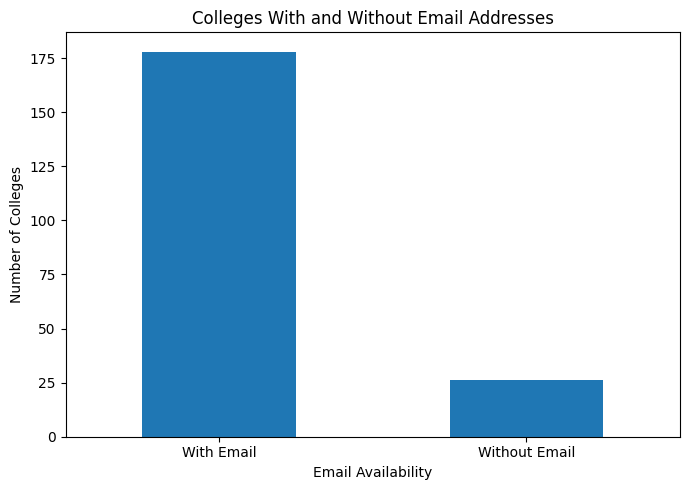

In [42]:
# Count colleges with and without email addresses
email_counts = df["Email Address"].notna().value_counts()

email_counts.index = email_counts.index.map({
    True: "With Email",
    False: "Without Email"
})

# Create a bar chart
email_counts.plot(kind="bar", figsize=(7, 5))

plt.title("Colleges With and Without Email Addresses")
plt.xlabel("Email Availability")
plt.ylabel("Number of Colleges")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observation 1:** Out of 204 colleges, 178 (87.25%) have email addresses recorded, while 26 (12.75%) do not. This indicates that email contact information is available for most colleges, although some records need further verification or updating.

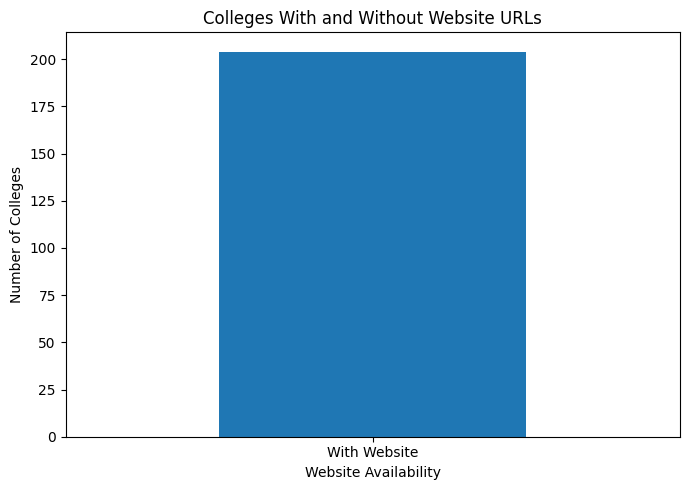

In [43]:
# Count colleges with and without website URLs
website_counts = df["Website URL"].notna().value_counts()

website_counts.index = website_counts.index.map({
    True: "With Website",
    False: "Without Website"
})

# Create a bar chart
website_counts.plot(kind="bar", figsize=(7, 5))

plt.title("Colleges With and Without Website URLs")
plt.xlabel("Website Availability")
plt.ylabel("Number of Colleges")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observation 2:** All 204 college records contain a website URL, and no missing website URLs were detected. This indicates complete website URL coverage in the extracted dataset. However, the URLs were checked for format only; their accessibility and correctness have not been verified.

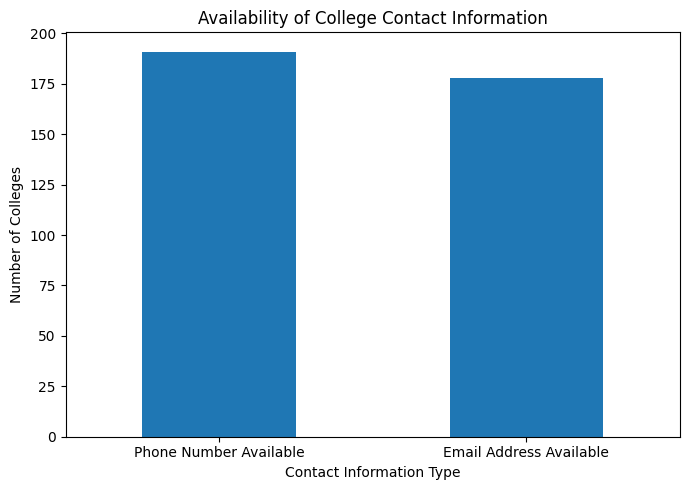

In [44]:
# Count available phone numbers and email addresses
contact_counts = pd.Series({
    "Phone Number Available": df["Contact Number"].notna().sum(),
    "Email Address Available": df["Email Address"].notna().sum()
})

# Create a bar chart
contact_counts.plot(kind="bar", figsize=(7, 5))

plt.title("Availability of College Contact Information")
plt.xlabel("Contact Information Type")
plt.ylabel("Number of Colleges")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observation 3:** Phone numbers are available for 191 colleges (93.63%), while email addresses are available for 178 colleges (87.25%). Phone contact information is more complete than email contact information in the extracted dataset. Missing contact details could be reviewed and updated to improve the usefulness of the directory.

In [45]:
# Generate summary statistics

total_colleges = len(df)

summary = pd.DataFrame({
    "Field": [
        "College Name",
        "Address",
        "Contact Number",
        "Email Address",
        "Website URL"
    ],
    "Available Records": [
        df["College Name"].notna().sum(),
        df["Address"].notna().sum(),
        df["Contact Number"].notna().sum(),
        df["Email Address"].notna().sum(),
        df["Website URL"].notna().sum()
    ],
    "Missing Records": [
        df["College Name"].isna().sum(),
        df["Address"].isna().sum(),
        df["Contact Number"].isna().sum(),
        df["Email Address"].isna().sum(),
        df["Website URL"].isna().sum()
    ]
})

print("Total colleges extracted:", total_colleges)
summary

Total colleges extracted: 204


,Field,Available Records,Missing Records
0,College Name,204,0
1,Address,204,0
2,Contact Number,191,13
3,Email Address,178,26
4,Website URL,204,0


### 5.2 Observations and Insights

1. **Email availability:** Out of 204 colleges, 178 (87.25%) have email addresses recorded, while 26 (12.75%) have missing email information.

2. **Phone number availability:** Contact numbers are available for 191 colleges (93.63%), while 13 (6.37%) have missing phone numbers.

3. **Website URL availability:** All 204 college records contain website URLs. No missing website URLs were detected, although the links have not been checked for accessibility.

4. **Duplicate records:** No duplicate rows or duplicate college names were found in the extracted dataset.

5. **Email data quality:** The email field required cleaning because some extracted text contained additional information. After cleaning, no invalid individual email formats were detected by the validation check.

6. **Contact information completeness:** Phone numbers are more frequently available than email addresses. Improving the availability of email addresses could make the directory more useful for electronic communication.

## 6. Key Findings & Recommendations

### 6.1 Key Findings

The web scraping project collected 204 college records from the Kerala University affiliated colleges directory. The dataset contains five fields: College Name, Address, Contact Number, Email Address, and Website URL.

The main findings are:

1. **College records extracted:** A total of 204 college records were collected.
2. **Email availability:** 178 colleges (87.25%) have email addresses, while 26 (12.75%) have missing email information.
3. **Phone availability:** 191 colleges (93.63%) have contact numbers, while 13 (6.37%) have missing phone information.
4. **Website URLs:** All 204 records contain website URLs. Their accessibility has not been verified.
5. **Duplicate records:** No duplicate rows or duplicate college names were found.
6. **Email validation:** After cleaning the extracted text, no invalid individual email formats were detected.
7. **Phone data quality:** Three phone entries initially contained extra website text. This text was removed without changing the phone numbers themselves.
8. **Data completeness:** Email addresses are the least complete of the three contact fields examined: phone number, email address, and website URL.

### 6.2 Data Quality Issues

The main data quality issues identified were missing phone numbers and email addresses, along with unwanted text included in some extracted contact fields. These issues were addressed through missing-value checks, text cleaning, and format validation.

The validation performed checks data format and completeness; it does not confirm that email addresses are active, phone numbers are correct, or website links are accessible.

### 6.3 Recommendations

- Update missing email addresses and phone numbers in the college directory.
- Review college contact information regularly to keep records current.
- Maintain consistent formatting for phone numbers, email addresses, and website URLs.
- Ensure that each college profile contains clearly separated contact fields.
- Periodically verify that website links are accessible and belong to the corresponding colleges.
- Use automated data validation to identify missing or incorrectly formatted information during future updates.